# Model Development #

$Step-1$: **load df_model**

In [1]:
import pandas as pd 

df_model = pd.read_pickle("df_model.pkl")
print(df_model.shape)
print(df_model["Churn"].value_counts())
df_model.dtypes

(6589, 32)
Churn
0    4720
1    1869
Name: count, dtype: int64


Gender                                object
Age                                    int64
Married                               object
Number of Dependents                   int64
City                                  object
Number of Referrals                    int64
Tenure in Months                       int64
Offer                                 object
Phone Service                         object
Avg Monthly Long Distance Charges    float64
Multiple Lines                        object
Internet Service                      object
Internet Type                         object
Avg Monthly GB Download              float64
Online Security                       object
Online Backup                         object
Device Protection Plan                object
Premium Tech Support                  object
Streaming TV                          object
Streaming Movies                      object
Streaming Music                       object
Unlimited Data                        object
Contract  

$Step-2$: **Check the categorical columns before encoding**

In [2]:
cat_cols = df_model.select_dtypes(include="object").columns      # this line will select only columns contains text
 
for col in cat_cols:
    print(col, "->" , df_model[col].nunique(), "unique values")  # nunique() = number of unique values 

Gender -> 2 unique values
Married -> 2 unique values
City -> 1106 unique values
Offer -> 6 unique values
Phone Service -> 2 unique values
Multiple Lines -> 3 unique values
Internet Service -> 2 unique values
Internet Type -> 4 unique values
Online Security -> 3 unique values
Online Backup -> 3 unique values
Device Protection Plan -> 3 unique values
Premium Tech Support -> 3 unique values
Streaming TV -> 3 unique values
Streaming Movies -> 3 unique values
Streaming Music -> 3 unique values
Unlimited Data -> 3 unique values
Contract -> 3 unique values
Paperless Billing -> 2 unique values
Payment Method -> 3 unique values


- City has 1106 unique values

- Every other text column has between 2 and 6. With only 6589 rows, that’s roughly 6 customers per city

- One-hot encoding City would add about 1100 columns,

      and the model would memorize individual cities instead of learning real churn patterns.
 
$Decision$: **drop City and one-hot encode the rest**

$Step-3$: **Drop City and one-hot encode**

In [3]:
df_encoded = df_model.drop(columns="City") # droped the city column

        # pd.get_dummies(df_encoded) = Each text column becomes True/False columns.
df_encoded = pd.get_dummies(df_encoded, drop_first=True, dtype=int)   
# When we use ""drop_first=True, dtype=int"" get_dummies sorts (alphabetical order) the unique values of each column and 
# drops the first one in that order. It has no idea which value is more meaningful.

print(df_encoded.shape)
df_encoded.head()

(6589, 48)


,Age,Number of Dependents,Number of Referrals,Tenure in Months,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,...,Streaming Movies_Yes,Streaming Music_None,Streaming Music_Yes,Unlimited Data_None,Unlimited Data_Yes,Contract_One Year,Contract_Two Year,Paperless Billing_Yes,Payment Method_Credit Card,Payment Method_Mailed Check
0,37,0,2,9,42.39,16.0,65.6,593.30,0.00,0,...,0,0,0,0,1,1,0,1,1,0
1,46,0,0,9,10.69,10.0,-4.0,542.40,38.33,10,...,1,0,1,0,0,0,0,0,1,0
2,50,0,0,4,33.65,30.0,73.9,280.85,0.00,0,...,0,0,0,0,1,0,0,1,0,0
3,78,0,1,13,27.82,4.0,98.0,1237.85,0.00,0,...,1,0,0,0,1,0,0,1,0,0
4,75,0,3,3,7.38,11.0,83.9,267.40,0.00,0,...,0,0,0,0,1,0,0,1,1,0


$Step-4$: **Split into features and target, then train and test sets**

In [4]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop(columns="Churn")    # It remove the Churn column, Becz Model should not see the answers. Holds the features
y = df_encoded["Churn"]     # "Churn" the target column, we are trying to predict.          

X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=0.2,      # test set (20%) and training set (80%)
                                                    random_state=42, 
                                                    stratify=y)     # When we split churn(6589 rows into train(5271) and split(1318). 
                                                            # churned in train_data = 1495*100/5271= 28.4% which is churn rate.
                                                            # churned in test_data = 374*100/1318 = 28.4% which is churn rate
                                                            # In full data 6589 rows, 1869 are churned. churn rate is 1869*100/6589=28.4 
                                                            # "stratify=y" keeps the churn ratio the same in both sets
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())         # 0.2836 and 0.2838: the churn rate is the same in both sets

(5271, 47) (1318, 47)
0.28362739518118 0.283763277693475


In [5]:
X_train.head()
X_test
y_train.head(20), y_test.head(20)   # y_train = 2370, 576, 5559..is the row index: the position of that customer
# y_test = 4196, 5678, 2267... is the row index:

# (0 or 1) is the Churn value for that customer: 1 means the customer churned, 0 means they stayed.

(2370    0
 576     0
 5559    1
 3564    1
 444     0
 5866    1
 44      0
 3250    0
 6960    0
 1490    1
 890     0
 629     1
 752     0
 5835    0
 3473    1
 1538    1
 4222    0
 588     0
 3405    0
 5950    0
 Name: Churn, dtype: int64,
 4196    0
 5678    1
 2267    0
 6252    0
 1822    1
 1305    0
 1402    1
 4605    0
 1654    1
 4734    0
 6361    0
 3081    0
 5384    0
 2543    0
 5248    0
 4132    0
 5442    0
 4626    0
 2212    0
 4052    0
 Name: Churn, dtype: int64)

$Step-5$: **Train a baseline model (Logistic Regression)**

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

baseline = Pipeline([("scaler", StandardScaler()),                                  # pipeline creating in this line
                     ("model", LogisticRegression(max_iter=1000, random_state=42))  # bundles the scaler and model into one object.
                    ])

baseline.fit(X_train, y_train)      # model is learning the patterns from feature data

y_pred = baseline.predict(X_test)          # this gives hard 0/1 predictions
y_prob = baseline.predict_proba(X_test)[:,1]   # this gives the probability of churn

print("Accuracy  :", accuracy_score(y_test, y_pred))
print("Precision :", precision_score(y_test, y_pred))
print("Recall    :", recall_score(y_test, y_pred))
print("F1        :", f1_score(y_test, y_pred))
print("ROC_AUC   :", roc_auc_score(y_test, y_prob))

Accuracy  : 0.8376327769347496
Precision : 0.7185792349726776
Recall    : 0.7032085561497327
F1        : 0.7108108108108108
ROC_AUC   : 0.9122405510740506


$Step-6$: **Log the baseline to MLflow**

In [9]:
%pip install mlflow

   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
    --------------------------------------- 0.3/12.0 MB ? eta -:--:--
   -- ------------------------------------- 0.8/12.0 MB 2.1 MB/s eta 0:00:06
   -- ------------------------------------- 0.8/12.0 MB 2.1 MB/s eta 0:00:06
   --- ------------------------------------ 1.0/12.0 MB 1.3 MB/s eta 0:00:09
   ---- ----------------------------------- 1.3/12.0 MB 1.5 MB/s eta 0:00:08
   ---- ----------------------------------- 1.3/12.0 MB 1.5 MB/s eta 0:00:08
   ------ --------------------------------- 1.8/12.0 MB 1.2 MB/s eta 0:00:09
   ------ --------------------------------- 2.1/12.0 MB 1.3 MB/s eta 0:00:08
   ------- -------------------------------- 2.4/12.0 MB 1.2 MB/s eta 0:00:08
   ------- -------------------------------- 2.4/12.0 MB 1.2 MB/s eta 0:00:08
   -------- ------------------------------- 2.6/12.0 MB 1.2 MB/s eta 0:00:08
   --------- ------------------------------ 2.9/12.0 MB 1.2 MB/s eta 0:00:08
   ----------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [15]:
import mlflow
import mlflow.sklearn

mlflow.set_experiment("churn_prediction")                        # creates an experiment

with mlflow.start_run(run_name = "baseline_logistic_regression"):  # opens one run, which is one training attempt.
    mlflow.log_param("model_type", "LogisticRegression")                           # Everything logged inside the with block is saved under that run
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("scaler", "StandardScaler")             # "log_param" records the settings you chose, model type, max_iter, and so on
    mlflow.log_param("test_size", 0.2)
    mlflow.log_param("random_state", 42)

    mlflow.log_metric("accuracy", accuracy_score(y_test, y_pred))             # log_metric records the scores
    mlflow.log_metric("precision", precision_score(y_test, y_pred))
    mlflow.log_metric("recall", recall_score(y_test, y_pred))
    mlflow.log_metric("f1", f1_score(y_test, y_pred))
    mlflow.log_metric("roc_auc", roc_auc_score(y_test, y_prob))

    mlflow.sklearn.log_model(baseline, name="model")      # this line, saves the whole pipeline

In [28]:
print(mlflow.set_experiment("churn_prediction").experiment_id)
print(mlflow.set_experiment("churn_prediction").name)
print(mlflow.set_experiment("churn_prediction").lifecycle_stage)
print(mlflow.set_experiment("churn_prediction").artifact_location)

1
churn_prediction
active
file:C:/DS_Py/08_project/mlruns/1


$Step-7$: **Open the MLflow UI**

In [16]:
import os
print(os.getcwd())

C:\DS_Py\08_project


$Step-8$: **Train a Random Forest**

In [23]:
# Cell A: train and evaluate

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200,  # means the forest has 200 trees. More trees give more stable results, but training takes longer
                           random_state=42,    # makes the result repeatable.
                           n_jobs=-1)        # n_jobs=-1 uses all your CPU cores to train faster

rf.fit(X_train, y_train)          # traning the model

rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:,1]

print("Accuracy  :", accuracy_score(y_test, rf_pred))
print("Precision :", precision_score(y_test, rf_pred))
print("Recall    :", recall_score(y_test, rf_pred))
print("F1        :", f1_score(y_test, rf_pred))
print("ROC_AUC   :", roc_auc_score(y_test, rf_prob))

Accuracy  : 0.8611532625189682
Precision : 0.8523985239852399
Recall    : 0.6176470588235294
F1        : 0.7162790697674418
ROC_AUC   : 0.9130350425994743


$Step-8b$: **Log the Random Forest to MLflow**

In [30]:
with mlflow.start_run(run_name="random_forest"):
    mlflow.log_param("model_type", "RandomForestClassifier")
    mlflow.log_param("n_estimators", 200)
    mlflow.log_param("test_size", 0.2)
    mlflow.log_param("random_state", 42)

    mlflow.log_metric("accuracy", accuracy_score(y_test, rf_pred))
    mlflow.log_metric("precision", precision_score(y_test, rf_pred))
    mlflow.log_metric("recall", recall_score(y_test, rf_pred))
    mlflow.log_metric("f1", f1_score(y_test, rf_pred))
    mlflow.log_metric("roc_auc", roc_auc_score(y_test, rf_prob))

    mlflow.sklearn.log_model(rf, name="model", skops_trusted_types=["sklearn.tree._tree.Tree"])

In [64]:
X_test

,Age,Number of Dependents,Number of Referrals,Tenure in Months,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,...,Streaming Movies_Yes,Streaming Music_None,Streaming Music_Yes,Unlimited Data_None,Unlimited Data_Yes,Contract_One Year,Contract_Two Year,Paperless Billing_Yes,Payment Method_Credit Card,Payment Method_Mailed Check
4196,33,2,4,13,13.77,23.0,72.80,930.05,0.0,0,...,0,0,0,0,1,0,0,1,0,0
5678,73,0,0,1,22.50,27.0,69.95,69.95,0.0,10,...,0,0,0,0,0,0,0,1,0,0
2267,35,0,0,16,20.65,0.0,20.10,296.15,0.0,0,...,0,1,0,1,0,1,0,0,1,0
6252,55,0,1,33,26.80,17.0,91.25,2964.05,0.0,130,...,1,0,1,0,0,0,0,0,0,0
1822,58,0,0,67,29.24,21.0,111.30,7482.10,0.0,0,...,1,0,1,0,1,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5122,76,0,7,11,24.42,29.0,70.20,834.70,0.0,0,...,0,0,0,0,1,0,1,1,0,0
455,20,0,8,21,0.00,59.0,28.50,629.35,0.0,0,...,0,0,0,0,1,0,0,0,0,0
6681,73,0,0,1,30.17,6.0,93.55,93.55,0.0,0,...,1,0,0,0,1,0,0,1,0,0
1426,50,0,0,55,8.93,26.0,73.10,4144.90,0.0,0,...,0,0,0,0,1,0,0,1,0,0


$Step-9$: **Test different probability cutoffs**

In [69]:
import pandas as pd

thresholds = [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]

rows = []
for name, prob in [("LogReg", y_prob),    # from logistic regression
                   ("RandomForest", rf_prob)]:    # from rf


    for t in thresholds:
        
        pred = (prob >= t).astype(int)
        rows.append({
            "model": name,
            "threshold": t,
            "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred),
        })

pd.DataFrame(rows).round(3)

,model,threshold,precision,recall,f1
0,LogReg,0.20,0.590,0.909,0.716
1,LogReg,0.25,0.610,0.888,0.723
2,LogReg,0.30,0.635,0.853,0.728
3,LogReg,0.35,0.665,0.818,0.734
4,LogReg,0.40,0.677,0.762,0.717
5,LogReg,0.45,0.689,0.727,0.707
6,LogReg,0.50,0.719,0.703,0.711
7,RandomForest,0.20,0.577,0.896,0.702
8,RandomForest,0.25,0.628,0.845,0.721
9,RandomForest,0.30,0.670,0.791,0.725


$Step-10$: **Log the tuned versions to MLflow**

In [72]:
tuned = [
    ("logreg_threshold_0.35", "LogisticRegression", y_prob, 0.35),
    ("random_forest_threshold_0.40", "RandomForestClassifier", rf_prob, 0.40),
]

for run_name, model_type, prob, t in tuned:
    pred = (prob >= t).astype(int)

    with mlflow.start_run(run_name=run_name):
        mlflow.log_param("model_type", model_type)
        mlflow.log_param("threshold", t)
        mlflow.log_param("test_size", 0.2)
        mlflow.log_param("random_state", 42)

        mlflow.log_metric("accuracy", accuracy_score(y_test, pred))
        mlflow.log_metric("precision", precision_score(y_test, pred))
        mlflow.log_metric("recall", recall_score(y_test, pred))
        mlflow.log_metric("f1", f1_score(y_test, pred))
        mlflow.log_metric("roc_auc", roc_auc_score(y_test, prob))

$Step-11$: **Which features drive churn?**

Tenure in Months                     0.135
Total Revenue                        0.105
Total Charges                        0.104
Monthly Charge                       0.069
Number of Referrals                  0.063
Total Long Distance Charges          0.060
Age                                  0.049
Contract_Two Year                    0.044
Avg Monthly Long Distance Charges    0.041
Avg Monthly GB Download              0.039
dtype: float64


<Axes: title={'center': 'Top 10 features (Random Forest)'}>

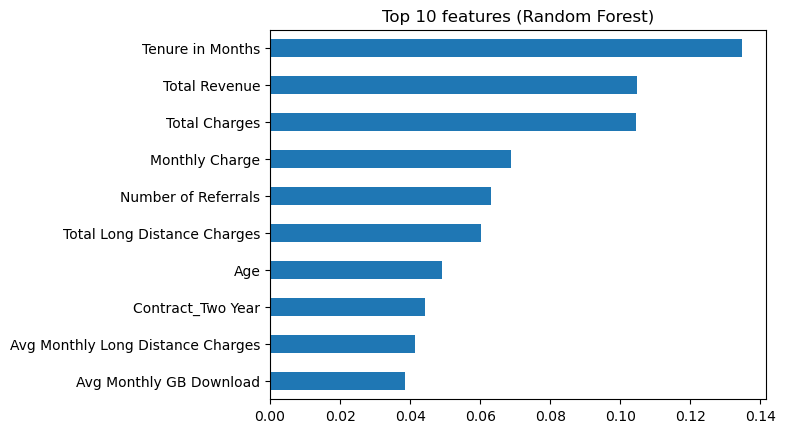

In [80]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns)  # "rf.feature_importances_" holds one importance score per feature, and the scores sum to 1
importances = importances.sort_values(ascending=False)                # "index=X_train.columns" attaches each score to its column name
# sort_values(ascending=False) puts the most important feature first

print(importances.head(10).round(3))

importances.head(10).sort_values().plot(kind="barh", title="Top 10 features (Random Forest)")

$Step 11b$: **Check the direction**

In [82]:
print(df_model.groupby("Contract")["Churn"].mean().round(3))     # splits customers by contract type and calculate the mean
tenure_bins = pd.cut(df_model["Tenure in Months"],
                     bins = [0, 12, 24, 48, df_model["Tenure in Months"].max()])

print(df_model.groupby(tenure_bins, observed=True)["Churn"].mean().round(3))

Contract
Month-to-Month    0.517
One Year          0.109
Two Year          0.026
Name: Churn, dtype: float64
Tenure in Months
(0, 12]     0.599
(12, 24]    0.287
(24, 48]    0.204
(48, 72]    0.095
Name: Churn, dtype: float64
